In [ ]:
# pip install scipy
# pip install matplotlib
# pip install pandas


/Users/yitxuenglim/.zshenv:.:1: no such file or directory: /Users/yitxuenglim/.cargo/env
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 21.8 MB/s  0:00:01m0:00:0100:01
Note: you may need to restart the kernel to use updated packages.


In [10]:
# Cell 1 — Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pearsonr
from pathlib import Path

OUTPUT_DIR = Path("report_figures")
OUTPUT_DIR.mkdir(exist_ok=True)

# Publication-friendly defaults
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

In [55]:
# Cell 2 — Figure 5a data

tracking_improvement = pd.DataFrame({
    "Motion": ["Push-up", "Squat", "Facedown", "The Worm"],
    "Velocity RMSE": [32, 56, 16, 41],
    "State RMSE": [12, 11, 44, 35],
})

tracking_improvement

,Motion,Velocity RMSE,State RMSE
0,Push-up,32,12
1,Squat,56,11
2,Facedown,16,44
3,The Worm,41,35


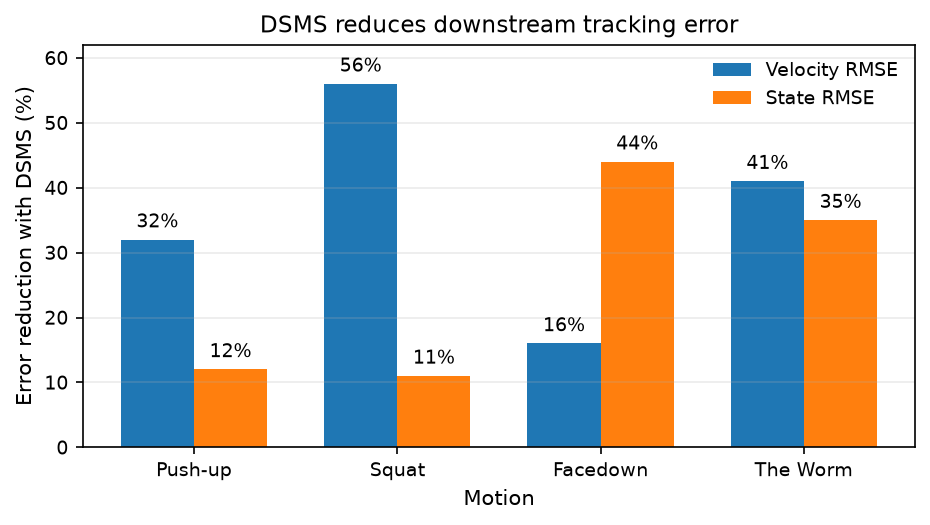

In [56]:
# Cell 3 — Plot Figure 5a

motions = tracking_improvement["Motion"].to_numpy()
velocity = tracking_improvement["Velocity RMSE"].to_numpy()
state = tracking_improvement["State RMSE"].to_numpy()

x = np.arange(len(motions))
width = 0.36

fig, ax = plt.subplots(figsize=(6.3, 3.6))

bars_velocity = ax.bar(
    x - width/2,
    velocity,
    width,
    label="Velocity RMSE",
)

bars_state = ax.bar(
    x + width/2,
    state,
    width,
    label="State RMSE",
)

ax.set_title("DSMS reduces downstream tracking error")
ax.set_ylabel("Error reduction with DSMS (%)")
ax.set_xlabel("Motion")

ax.set_xticks(x)
ax.set_xticklabels(motions)

ax.set_ylim(0, 62)
ax.grid(axis="y", alpha=0.25)

ax.legend(frameon=False)

# Value annotations
for bars in [bars_velocity, bars_state]:
    for bar in bars:
        value = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            value + 1.2,
            f"{value:.0f}%",
            ha="center",
            va="bottom",
            fontsize=9,
        )

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "fig5a_dsms_tracking_improvement.pdf",
    bbox_inches="tight"
)
fig.savefig(
    OUTPUT_DIR / "fig5a_dsms_tracking_improvement.png",
    bbox_inches="tight"
)

plt.show()

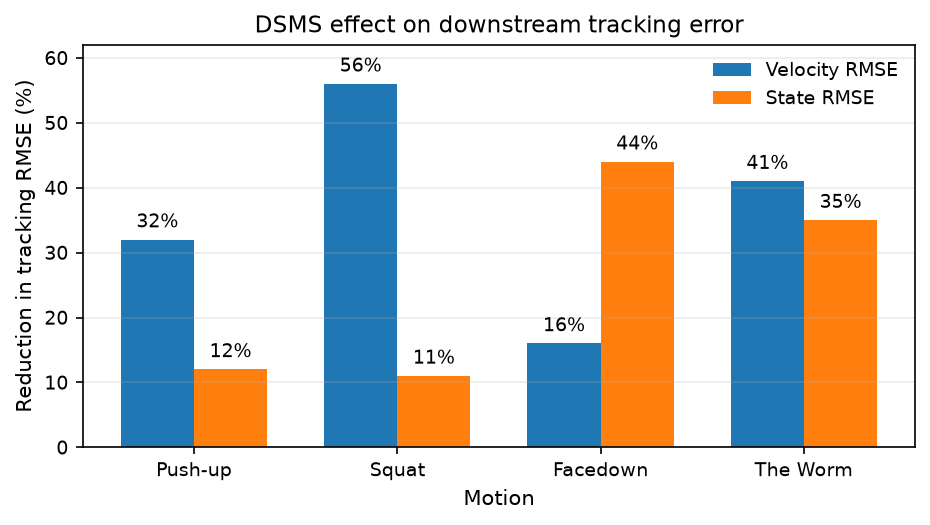

In [57]:
# Cell 3 — Figure 5(a): DSMS effect on downstream tracking

motions = tracking_improvement["Motion"].to_numpy()
velocity = tracking_improvement["Velocity RMSE"].to_numpy()
state = tracking_improvement["State RMSE"].to_numpy()

x = np.arange(len(motions))
width = 0.36

fig, ax = plt.subplots(figsize=(6.3, 3.6))

bars_velocity = ax.bar(
    x - width/2,
    velocity,
    width,
    label="Velocity RMSE",
)

bars_state = ax.bar(
    x + width/2,
    state,
    width,
    label="State RMSE",
)

ax.set_title("DSMS effect on downstream tracking error")

ax.set_ylabel("Reduction in tracking RMSE (%)")
ax.set_xlabel("Motion")

ax.set_xticks(x)
ax.set_xticklabels(motions)

ax.set_ylim(0, 62)
ax.grid(axis="y", alpha=0.25)

ax.legend(frameon=False)

# Value labels
for bars in [bars_velocity, bars_state]:
    for bar in bars:
        value = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width()/2,
            value + 1.2,
            f"{value:.0f}%",
            ha="center",
            va="bottom",
            fontsize=9,
        )

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "fig5a_dsms_tracking_improvement.pdf",
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "fig5a_dsms_tracking_improvement.png",
    bbox_inches="tight"
)

plt.show()

In [58]:
# Cell 4 — Figure 5b data

learning_efficiency = pd.DataFrame({
    "Motion": [
        "Push-up",
        "Squat",
        "Facedown",
        "The Worm",
    ],
    "GhostGUI": [
        1000,
        4497,
        30000,   # threshold NOT reached
        5591,
    ],
    "DSMS": [
        1000,
        2340,
        2201,
        10567,
    ],
})

# Record threshold failures separately
threshold_not_reached = {
    ("Facedown", "GhostGUI")
}

learning_efficiency

,Motion,GhostGUI,DSMS
0,Push-up,1000,1000
1,Squat,4497,2340
2,Facedown,30000,2201
3,The Worm,5591,10567


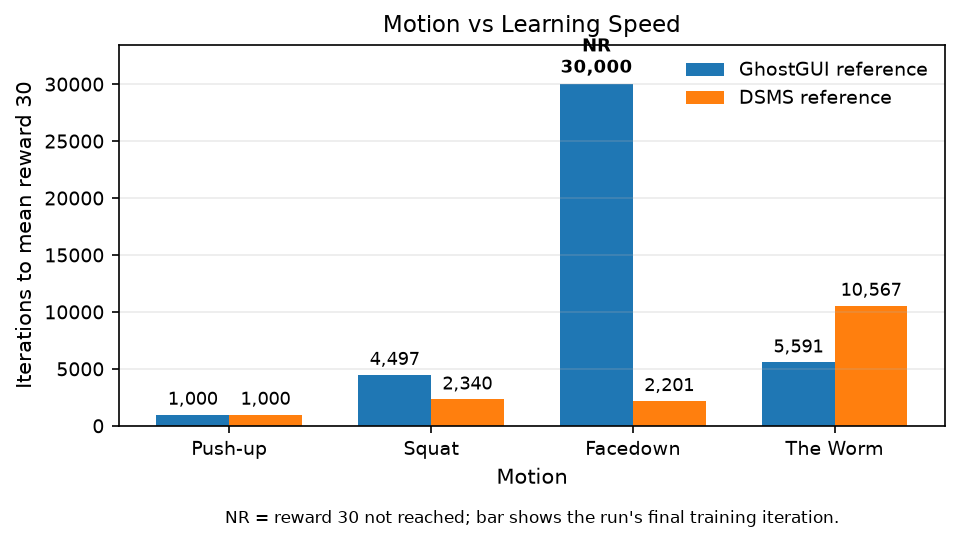

In [59]:
# Cell 5 — Plot Figure 5b

motions = learning_efficiency["Motion"].to_numpy()
gg = learning_efficiency["GhostGUI"].to_numpy()
dsms = learning_efficiency["DSMS"].to_numpy()

x = np.arange(len(motions))
width = 0.36

fig, ax = plt.subplots(figsize=(6.5, 3.8))

bars_gg = ax.bar(
    x - width/2,
    gg,
    width,
    label="GhostGUI reference",
)

bars_dsms = ax.bar(
    x + width/2,
    dsms,
    width,
    label="DSMS reference",
)

ax.set_title("Motion vs Learning Speed")
ax.set_ylabel("Iterations to mean reward 30")
ax.set_xlabel("Motion")

ax.set_xticks(x)
ax.set_xticklabels(motions)

ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

# Annotate GhostGUI values
for i, bar in enumerate(bars_gg):
    motion = motions[i]
    value = gg[i]

    if (motion, "GhostGUI") in threshold_not_reached:
        label = "NR\n30,000"
        fontweight = "bold"
    else:
        label = f"{value:,}"
        fontweight = "normal"

    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 500,
        label,
        ha="center",
        va="bottom",
        fontsize=8.5,
        fontweight=fontweight,
    )

# Annotate DSMS values
for i, bar in enumerate(bars_dsms):
    value = dsms[i]

    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 500,
        f"{value:,}",
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

ax.set_ylim(0, 33500)

# Explanation in the plot
ax.text(
    0.5,
    -0.22,
    "NR = reward 30 not reached; bar shows the run's final training iteration.",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=8,
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "fig5b_learning_efficiency.pdf",
    bbox_inches="tight"
)
fig.savefig(
    OUTPUT_DIR / "fig5b_learning_efficiency.png",
    bbox_inches="tight"
)

plt.show()

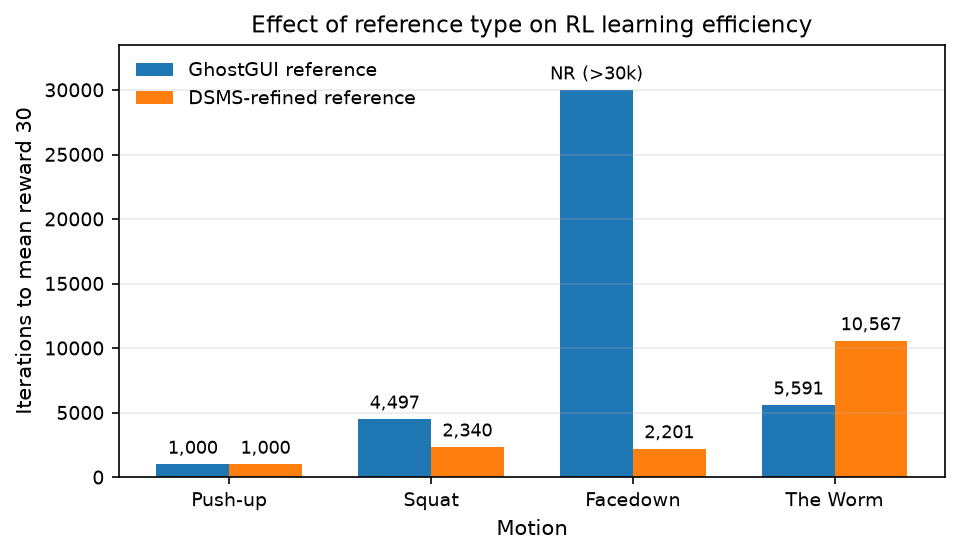

In [60]:
# Cell 5 — Figure 5(b): RL learning efficiency

motions = learning_efficiency["Motion"].to_numpy()
gg = learning_efficiency["GhostGUI"].to_numpy()
dsms = learning_efficiency["DSMS"].to_numpy()

x = np.arange(len(motions))
width = 0.36

fig, ax = plt.subplots(figsize=(6.5, 3.8))

bars_gg = ax.bar(
    x - width/2,
    gg,
    width,
    label="GhostGUI reference",
)

bars_dsms = ax.bar(
    x + width/2,
    dsms,
    width,
    label="DSMS-refined reference",
)

ax.set_title("Effect of reference type on RL learning efficiency")

ax.set_ylabel("Iterations to mean reward 30")
ax.set_xlabel("Motion")

ax.set_xticks(x)
ax.set_xticklabels(motions)

ax.set_ylim(0, 33500)
ax.grid(axis="y", alpha=0.25)

ax.legend(frameon=False)

# GhostGUI value labels
for i, bar in enumerate(bars_gg):
    motion = motions[i]
    value = gg[i]

    if (motion, "GhostGUI") in threshold_not_reached:
        label = "NR (>30k)"
    else:
        label = f"{value:,}"

    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 500,
        label,
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

# DSMS value labels
for i, bar in enumerate(bars_dsms):
    value = dsms[i]

    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 500,
        f"{value:,}",
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "fig5b_learning_efficiency.pdf",
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "fig5b_learning_efficiency.png",
    bbox_inches="tight"
)

plt.show()

In [53]:
# Cell 6 — SYNTHETIC Figure 6 data
#
# IMPORTANT:
# These values are visual approximations for reproducing the figure.
# Replace them with your actual experimental results before submission.

reference_quality_demo = pd.DataFrame([
    # motion, source, jerk RMS [rad/s^3], clean rollout state RMSE



    ["Crawlstand",  "DSMS",        42, 1.1],
    ["Facedown",    "GhostGUI",   210, 1.42],

    ["The Worm",    "GhostGUI",  3000, 1.74],
    ["The Worm",    "DSMS",      1250, 1.12],

    ["Crawlstand",  "GhostGUI",   102, 1.2],

    ["Lunges",      "DSMS",        64, 0.58],
    ["Lunges",      "GhostGUI",   310, 0.68],

    ["Squat",       "GhostGUI",   480, 0.84],
    ["Squat",       "DSMS",        55, 0.75],

    ["Push-up",     "GhostGUI",    95, 0.83],
    ["Push-up",     "DSMS",        72, 0.76],



    ["Kneel",       "DSMS",        29, 0.63],
    ["Kneel",       "GhostGUI",    37, 0.71],

    ["Lunges 2",    "DSMS",        65, 0.61],
    ["Lunges 2",    "GhostGUI",   230, 0.82],

    ["Facedown",    "DSMS",        52, 0.65],

    ["Crawlstand 2","DSMS",        68, 0.72],
    ["Crawlstand 2","GhostGUI",   228, 0.80],
], columns=[
    "Motion",
    "Reference",
    "Jerk_RMS",
    "State_RMSE",
])

reference_quality_demo

,Motion,Reference,Jerk_RMS,State_RMSE
0,Crawlstand,DSMS,42,1.10
1,Facedown,GhostGUI,210,1.42
2,The Worm,GhostGUI,3000,1.74
3,The Worm,DSMS,1250,1.12
4,Crawlstand,GhostGUI,102,1.20
5,Lunges,DSMS,64,0.58
6,Lunges,GhostGUI,310,0.68
7,Squat,GhostGUI,480,0.84
8,Squat,DSMS,55,0.75
9,Push-up,GhostGUI,95,0.83


In [54]:
# Cell 7 — Correlation

# Because jerk spans several orders of magnitude and the figure uses a
# logarithmic x-axis, this demo computes correlation on log10(jerk).
#
# VERIFY THIS against the analysis used for your original SURF presentation.

x_log = np.log10(reference_quality_demo["Jerk_RMS"])
y = reference_quality_demo["State_RMSE"]

r, p = pearsonr(x_log, y)

print(f"r = {r:.3f}")
print(f"p = {p:.4g}")
print(f"n = {len(reference_quality_demo)}")

r = 0.654
p = 0.003208
n = 18


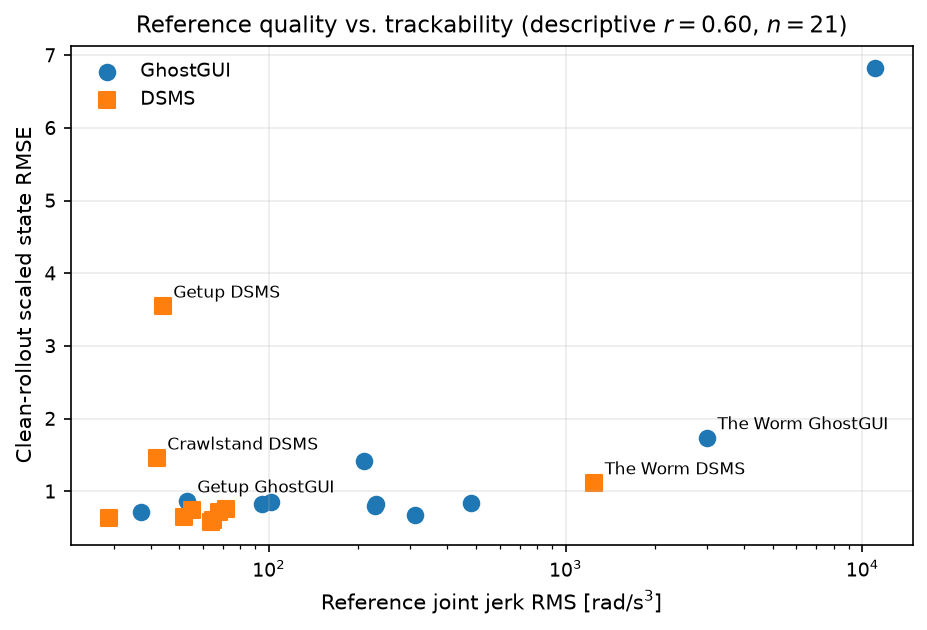

In [31]:
# Cell 8 — Plot Figure 6

fig, ax = plt.subplots(figsize=(6.3, 4.3))

for reference, marker in [
    ("GhostGUI", "o"),
    ("DSMS", "s"),
]:
    subset = reference_quality_demo[
        reference_quality_demo["Reference"] == reference
    ]

    ax.scatter(
        subset["Jerk_RMS"],
        subset["State_RMSE"],
        marker=marker,
        s=55,
        label=reference,
    )

ax.set_xscale("log")

ax.set_title(
    f"Reference quality vs. trackability "
    f"(descriptive $r={r:.2f}$, $n={len(reference_quality_demo)}$)"
)

ax.set_xlabel(r"Reference joint jerk RMS [rad/s$^3$]")
ax.set_ylabel("Clean-rollout scaled state RMSE")

ax.grid(alpha=0.25)
ax.legend(frameon=False)

# Label only the most informative points.
# This is much cleaner than labeling all 21 points in the paper.
labels_to_show = {
    ("Getup", "GhostGUI"),
    ("Getup", "DSMS"),
    ("Crawlstand", "DSMS"),
    ("The Worm", "GhostGUI"),
    ("The Worm", "DSMS"),
}

for _, row in reference_quality_demo.iterrows():
    key = (row["Motion"], row["Reference"])

    if key in labels_to_show:
        ax.annotate(
            f'{row["Motion"]} {row["Reference"]}',
            (row["Jerk_RMS"], row["State_RMSE"]),
            xytext=(5, 4),
            textcoords="offset points",
            fontsize=8,
        )

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "fig6_reference_quality_trackability.pdf",
    bbox_inches="tight"
)
fig.savefig(
    OUTPUT_DIR / "fig6_reference_quality_trackability.png",
    bbox_inches="tight"
)

plt.show()

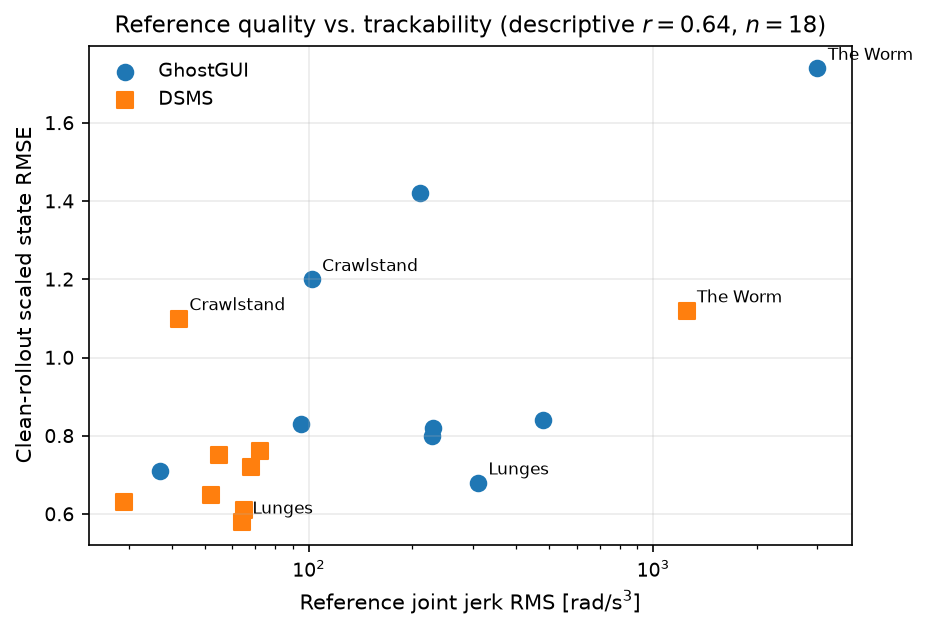

In [38]:
# Cell 8 — Plot Figure 6

fig, ax = plt.subplots(figsize=(6.3, 4.3))

for reference, marker in [
    ("GhostGUI", "o"),
    ("DSMS", "s"),
]:
    subset = reference_quality_demo[
        reference_quality_demo["Reference"] == reference
    ]

    ax.scatter(
        subset["Jerk_RMS"],
        subset["State_RMSE"],
        marker=marker,
        s=55,
        label=reference,
    )

ax.set_xscale("log")

ax.set_title(
    f"Reference quality vs. trackability "
    f"(descriptive $r={r:.2f}$, $n={len(reference_quality_demo)}$)"
)

ax.set_xlabel(r"Reference joint jerk RMS [rad/s$^3$]")
ax.set_ylabel("Clean-rollout scaled state RMSE")

ax.grid(alpha=0.25)
ax.legend(frameon=False)

# Only label Crawlstand and The Worm.
# Both GhostGUI and DSMS points are labelled,
# but the annotation shows only the motion name.
labels_to_show = {
    ("Crawlstand", "GhostGUI"),
    ("Crawlstand", "DSMS"),
    ("The Worm", "GhostGUI"),
    ("The Worm", "DSMS"),
    ("Lunges", "GhostGUI"),
    ("Lunges", "DSMS"),

}

for _, row in reference_quality_demo.iterrows():
    key = (row["Motion"], row["Reference"])

    if key in labels_to_show:
        ax.annotate(
            row["Motion"],
            (row["Jerk_RMS"], row["State_RMSE"]),
            xytext=(5, 4),
            textcoords="offset points",
            fontsize=8,
        )

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "fig6_reference_quality_trackability.pdf",
    bbox_inches="tight"
)
fig.savefig(
    OUTPUT_DIR / "fig6_reference_quality_trackability.png",
    bbox_inches="tight"
)

plt.show()

In [24]:
# Cell 9 — Optional matched 6-point analysis
#
# SYNTHETIC approximations from the presentation slide.
# Replace with real values before use in the report.

matched_demo = pd.DataFrame([
    ["Crawlstand", "DSMS",       42, 0.84],
    ["Crawlstand", "GhostGUI",  102, 0.85],

    ["Lunges",     "DSMS",       64, 0.58],
    ["Lunges",     "GhostGUI",  310, 0.68],

    ["The Worm",   "DSMS",     1250, 1.13],
    ["The Worm",   "GhostGUI", 3000, 1.73],
], columns=[
    "Motion",
    "Reference",
    "Jerk_RMS",
    "State_RMSE",
])

r_matched, p_matched = pearsonr(
    np.log10(matched_demo["Jerk_RMS"]),
    matched_demo["State_RMSE"],
)

print(f"Matched-set r = {r_matched:.3f}")
print(f"n = {len(matched_demo)}")

Matched-set r = 0.828
n = 6
